# Climate risk in thirty years of ESA listing decisions
**Yanghong Liu (@yanghong-liu) and @chunminzheng — ESPM 157, Module 3**

Climate change can increase extinction risk through habitat loss, drought, fire, and flooding.
An agency's explanation records which risks were considered when protection was granted.
Final listing rules also contain comments and references, so finding the words "climate change"
is different from finding the agency's own risk assessment.

This notebook combines a corpus audit, phrase retrieval, and source-linked classifications for
FWS protection rules from 1996–2025. It traces results to source passages and compares selected
cases with an independent dataset.

Sources: [course module](https://github.com/espm-157/text-template),
[Delach et al. (2019)](https://doi.org/10.1038/s41558-019-0620-8), and
[independent data](https://doi.org/10.17605/OSF.IO/R9UCA).

## A precise question and a fixed scope
**Main question:** In FWS initial final ESA listing rules and decisions adding previously uncovered populations/range from **1996–2025**, how often does the
agency explicitly identify climate change as a threat, and how does that change over time?

The scope excludes pure similarity-of-appearance rules and includes genuinely new geographic or
population protection, while excluding pure renaming, resegmentation, and status changes.
- Include animals and plants; one rule is one observation, even when it covers multiple species.
- Restrict the agency to the **U.S. Fish and Wildlife Service**. This does not cover all NOAA/NMFS rules.
- Include initial final endangered and threatened listings, including rules that also designate
  critical habitat or add a 4(d) rule. Exclude standalone habitat designations, delistings,
  reclassifications, corrections, emergency temporary rules, pure appearance-based rules, and unrelated actions.
- Include a first permanent final listing after temporary emergency protection. Foreign taxa listed
  under the ESA are included; the scope is FWS rulemaking, not only U.S.-native species.
- Exclude FWS administrative copies of prior NMFS determinations; joint original determinations can qualify.
- The 30 complete calendar years are 1996 through 2025. A year with no screened candidates has
  no estimated proportion; it is not assigned a zero threat rate.

**Label definitions for source review**
1. `agency_threat`: the agency itself identifies climate change as contributing to the species' risk.
2. `mention_only`: the wording appears, but the passage does not establish that agency finding
   (for example a question in a public comment, a citation, or a rejected claim).
3. `uncertain`: context is insufficient or attribution remains unclear; inspect the full source.

The first computation below measures **wording**, not the main outcome. A climate keyword hit
does not establish `agency_threat`. Impacts described without those exact words may be missed.

For the semantic outcome, a current **or future** adverse contribution to at least one newly
protected target qualifies, including a potential or synergistic risk. Climate need not be the
only reason for listing, and the agency need not quantify every mechanism. Natural or human-caused
long-term climate changes can qualify; this is not an anthropogenic-attribution analysis. Geological
history, a generic definition, and ordinary weather without an identified climate contribution do
not qualify. An explicit refusal to establish a threat is `mention_only`; unresolved interpretation
or conflicting source statements remain `uncertain`. The butterfly and lynx examples below show
why a simple search or blanket negation rule is insufficient.

A listing rule announces endangered or threatened status and extends federal protection.
Section 4 considers five types of factors: habitat loss or modification; overuse for commercial,
recreational, scientific, or educational purposes; disease or predation; inadequate existing
regulation; and other natural or human-caused factors. Climate effects can act through more
than one category. These factors are stated in the actual
[Southern Sierra Nevada fisher rule](https://www.federalregister.gov/documents/2020/05/15/2020-09153/endangered-and-threatened-wildlife-and-plants-endangered-species-status-for-southern-sierra-nevada).
This is a study of published agency reasoning, not an estimate of which species are biologically
affected by climate change or of the legal effect of listing.

## Match each tool to a task
The workflow separates retrieval, selection, interpretation, and validation:

- **API metadata retrieval** establishes the denominator without filtering on climate words.
  Pagination and unique identifiers check the completeness of that specific query.
- **Title and SUMMARY rules** provide an inspectable eligibility screen. Body-text checks resolve
  actions such as extensions, corrections, and changes to an existing listing.
- **Regular expressions** retrieve explicit phrases quickly and transparently. Their limitations
  can be demonstrated with missed plurals, historical references, and unadopted comments.
- **Source-linked interpretation** addresses speaker, negation, future risk, and interacting threats.
  Exact passages and context are saved so a label can be challenged. Saved annotations are replayed
  rather than treated as a new deterministic classifier.
- **Independent cases and sensitivity checks** test comparability and the consequences of choices.
  Source hashes test integrity, not semantic accuracy.

Run this notebook from the repository directory using `requirements.txt`. Timings measure the
executed retrieval and replay stages only; no unsupported speed, cost, or accuracy claims are made.

In [1]:
from pathlib import Path
from time import perf_counter
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from esa_tools import (START, END, collect_metadata, screen_metadata,
                       download_texts, passage_table, delach_data)

ROOT = Path.cwd()
assert (ROOT / 'esa_tools.py').exists(), 'Run the notebook from the repository directory.'
for directory in ['sources', 'results', 'review']:
    (ROOT / directory).mkdir(exist_ok=True)
print({'python': platform.python_version(), 'start': START, 'end': END,
       'agency': 'FWS', 'unit': 'rule document', 'species_scope': 'animals and plants'})

{'python': '3.11.0', 'start': '1996-01-01', 'end': '2025-12-31', 'agency': 'FWS', 'unit': 'rule document', 'species_scope': 'animals and plants'}


## Build the denominator before searching for climate
Retrieve **all FWS documents of type RULE** in the date interval, without a climate keyword filter.
The downloader follows pagination and checks both the API count and unique document numbers.
The metadata snapshot, exact query URLs, retrieval time, and SHA-256 are saved in `sources/`.
This checks retrieval completeness for this API query, not the scientific correctness of our screen.

In [2]:
metadata = collect_metadata(ROOT)
assert metadata.document_number.is_unique
assert metadata.publication_date.between(START, END).all()
print(f'{len(metadata):,} FWS rule records retrieved.')
display(metadata[['document_number', 'publication_date', 'title', 'action']].head())
display(json.loads((ROOT / 'sources/retrieval_manifest.json').read_text()))

1,534 FWS rule records retrieved.


,document_number,publication_date,title,action
0,96-795,1996-01-24,Importation of Exotic Wild Birds to the United...,Final rule.
1,96-1338,1996-01-26,Export of River Otters Taken in Tennessee in t...,Final rule.
2,96-1880,1996-02-02,"Conferring Designated Port Status on Atlanta, GA",Final rule.
3,96-2488,1996-02-06,Endangered and Threatened Wildlife and Plants;...,Final rule.
4,96-3186,1996-02-14,Subsistence Management Regulations for Public ...,Correcting amendments.


{'retrieved_at_utc': '2026-10-28T19:15:23.420991+00:00',
 'api_record_count': 1534,
 'query_urls': ['https://www.federalregister.gov/api/v1/documents.json?conditions%5Bagencies%5D%5B%5D=fish-and-wildlife-service&conditions%5Btype%5D%5B%5D=RULE&conditions%5Bpublication_date%5D%5Bgte%5D=1996-01-01&conditions%5Bpublication_date%5D%5Blte%5D=2025-12-31&per_page=1000&order=oldest&fields%5B%5D=document_number&fields%5B%5D=title&fields%5B%5D=publication_date&fields%5B%5D=action&fields%5B%5D=raw_text_url&fields%5B%5D=html_url&fields%5B%5D=abstract&fields%5B%5D=type&page=1',
  'https://www.federalregister.gov/api/v1/documents.json?conditions%5Bagencies%5D%5B%5D=fish-and-wildlife-service&conditions%5Btype%5D%5B%5D=RULE&conditions%5Bpublication_date%5D%5Bgte%5D=1996-01-01&conditions%5Bpublication_date%5D%5Blte%5D=2025-12-31&per_page=1000&order=oldest&fields%5B%5D=document_number&fields%5B%5D=title&fields%5B%5D=publication_date&fields%5B%5D=action&fields%5B%5D=raw_text_url&fields%5B%5D=html_url&fie

## Trace why the denominator changed
The original 296-document snapshot is frozen in `sources/initial_296_candidates.csv`.
The eligibility audit is reproducible with `python corpus_audit.py --download` on a fresh clone.
Each row records the rule category, decision, reason, source excerpt, section, offsets, URL,
and checksums. The two scope definitions are saved in `review/corpus_policy.json`.
The table below is computed from these records.


In [3]:
audit = pd.read_csv(ROOT / 'review/corpus_audit.csv', keep_default_na=False)
assert audit.document_number.is_unique
assert audit.audit_decision.isin(['include', 'exclude']).all(), 'Resolve pending audit cases before a final denominator.'
display(audit.groupby(['initial_candidate', 'audit_decision']).size().unstack(fill_value=0))
display(audit[audit.audit_decision.eq('exclude')].groupby('audit_category').size().to_frame('excluded documents'))
policies = json.loads((ROOT / 'review/corpus_policy.json').read_text())
display(pd.DataFrame([{'policy': k, 'decision': v['decision'], 'scope_definition': v['meaning']} for k,v in policies.items()]))
display(audit[audit.audit_decision.eq('exclude')][['document_number','title','reason_en','evidence_text','html_url']].head(6))

audit_decision,exclude,include
initial_candidate,,
False,21,34
True,27,269


,excluded documents
audit_category,
affirmation_of_prior_rule,1
cites_trade_rule,3
comment_period_notice,3
correction,1
court_order_restoration,1
delisting,5
delisting_after_remand,1
effective_date_delay,1
existing_listing_resegmented,2


,policy,decision,scope_definition
0,pure_similarity_of_appearance,exclude,Exclude rules providing only appearance-based ...
1,new_geographic_protection,include,Include rules that add previously uncovered po...


,document_number,title,reason_en,evidence_text,html_url
3,96-23451,Endangered and Threatened Wildlife and Plants;...,FWS administratively inserts an NMFS-jurisdict...,The U.S. Fish and Wildlife Service (FWS) is ad...,https://www.federalregister.gov/documents/1996...
7,96-29694,Endangered and Threatened Wildlife and Plants;...,FWS administratively inserts an NMFS-jurisdict...,The U.S. Fish and Wildlife Service (FWS) is ad...,https://www.federalregister.gov/documents/1996...
40,98-12803,Amendment to Appendix III Listing of Bigleaf M...,"A CITES Appendix III trade-list amendment, not...",This rule announces an amendment to the Append...,https://www.federalregister.gov/documents/1998...
53,98-28927,Amendment by Brazil to Appendix III Listing of...,"A CITES Appendix III trade-list amendment, not...",This rule announces an amendment to the Append...,https://www.federalregister.gov/documents/1998...
65,99-14928,Amendment by Mexico to Appendix III Listing of...,"A CITES Appendix III trade-list amendment, not...",This rule announces an amendment to the Append...,https://www.federalregister.gov/documents/1999...
104,01-970,Endangered and Threatened Wildlife and Plants;...,Reopens comments on an earlier decision; does ...,"l. v. Michael Spear, et al. (Case No. CIV-R-99...",https://www.federalregister.gov/documents/2001...


## Apply the corpus audit
The original title screen selected 296 candidates. `corpus_audit.py` checks the actual SUMMARY,
ACTION, document identity, and relevant body text. It distinguishes a current legal action from
references to past or proposed actions and records source excerpts, offsets, and checksums.

The original set contains 269 eligible documents and 27 exclusions. A second metadata search and
residual-title check added 55 source inspections: 34 qualify and 21 do not. The current corpus
contains 303 documents. These checks reduce omissions but do not establish perfect recall.
See `review/corpus_audit.csv`, `review/additional_candidate_metadata.csv`, and
`review/residual_metadata_check.csv`.

An earlier audit reported 304 rules. Further body-text checking showed that the 2011 loggerhead
turtle rule creates nine DPS classifications but adds no previously unprotected range: worldwide
protection began in 1978. Applying the same rule already used for green turtles excludes it,
leaving 303. This correction shows why a positive SUMMARY signal alone cannot certify first protection.

In [4]:
screened = screen_metadata(metadata, ROOT)
screened.to_csv(ROOT / 'results/corpus_screen.csv', index=False)
display(screened.screen_status.value_counts().rename_axis('automatic category').to_frame('rules'))
corpus = screened.loc[screened.included].copy()
print(f'{len(corpus)} rules included under the source audit and recorded scope.')
display(corpus[['document_number', 'publication_date', 'title']].head())

,rules
automatic category,
exclude_other_action,1087
candidate_initial_listing,296
needs_title_review,151


303 rules included under the source audit and recorded scope.


,document_number,publication_date,title
12,96-12901,1996-05-23,Endangered and Threatened Wildlife and Plants;...
20,96-19963,1996-08-07,Endangered and Threatened Wildlife and Plants;...
22,96-21334,1996-08-21,Endangered and Threatened Wildlife and Plants;...
35,96-25462,1996-10-07,Endangered and Threatened Wildlife and Plants;...
36,96-25558,1996-10-10,Endangered and Threatened Wildlife and Plants;...


## Keep text and evidence traceable
Download the rules included by the current audited selection. Raw texts are cached in the git-ignored `data/` folder.
For new downloads, use the official GovInfo archive for the same document number and publication
date, with Federal Register raw text as a fallback. Transient connection and timeout failures are retried. `sources/text_download_manifest.csv` records the
actual text URL and checksum for each rule; an unsuccessful fallback stops the analysis.
Each passage keeps a stable document number, passage number, source URL, and neighboring context.
Raw blank-line blocks can contain page breaks and multiple voices. We normalize whitespace and
split long blocks at sentence boundaries, targeting 1,200 characters without truncating sentences.
These are source passages, not guaranteed original paragraphs. Block numbers and character offsets
record their locations. Abbreviations can affect sentence splitting; inspect neighboring context
and the original rule when attribution is unclear.

The explicit pattern covers "climate change", "global warming", "climatic change", and
"changing climate". A separate broader pattern covers sea-level rise and ocean acidification.
The latter is a sensitivity check; these phrases alone do not establish human-caused climate change.

Some raw_text_url responses contain an HTML PRE wrapper. The reader extracts its text and removes
markup before passage splitting; original cached responses and their hashes remain unchanged.

In [5]:
texts = download_texts(corpus, ROOT)
started = perf_counter()
passages = passage_table(corpus, texts)
regex_seconds = perf_counter() - started
print(f'{len(texts):,} texts; {sum(map(len, texts.values())):,} characters; '
      f'{len(passages):,} passages.')
print(f'Passage preparation and pattern matching took {regex_seconds:.3f} seconds on this run.')
print(f'Passage table memory: {passages.memory_usage(deep=True).sum()/1024**2:.1f} MiB.')
hits = passages[passages.explicit_match].copy()
display(hits[['passage_id', 'year', 'title', 'text', 'source_url']].head(5))

303 texts; 49,389,023 characters; 77,101 passages.
Passage preparation and pattern matching took 2.826 seconds on this run.
Passage table memory: 192.3 MiB.


,passage_id,year,title,text,source_url
1043,97-130:p0093,1997,Endangered and Threatened Wildlife and Plants;...,Comment: AGFD herpetologist Jeff Howland is ci...,https://www.federalregister.gov/documents/1997...
3115,97-15300:p0044,1997,Endangered and Threatened Wildlife and Plants;...,The decline in populations of amphibians has b...,https://www.federalregister.gov/documents/1997...
3746,97-20879:p0019,1997,Endangered and Threatened Wildlife and Plants;...,"1967, Schaffer 1993). The maritime climate of ...",https://www.federalregister.gov/documents/1997...
5332,98-12828:p0071,1998,Endangered and Threatened Wildlife and Plants;...,"In accordance with policy promulgated July 1, ...",https://www.federalregister.gov/documents/1998...
12429,00-7145:p0172,2000,Endangered and Threatened Wildlife and Plants;...,The lynx that were recently introduced into Co...,https://www.federalregister.gov/documents/2000...


## A baseline of explicit wording, not a threat-classification result
For each rule, calculate whether at least one passage contains an explicit phrase. This includes
comments and references. The figure therefore measures **keyword mentions in the automatically audited corpus**.
It must not be captioned as the proportion of species threatened by climate change, or as a final
agency finding. Showing both numerator and denominator makes changes in the number of rules visible.

,rules,explicit_mentions,broader_mentions,explicit_mention_fraction
year,,,,
1996,7,0,0,0.000000
1997,27,3,0,0.111111
1998,22,1,0,0.045455
1999,18,0,0,0.000000
2000,27,2,0,0.074074
2001,7,0,0,0.000000
2002,10,1,0,0.100000
2003,4,1,0,0.250000
2004,5,0,1,0.000000


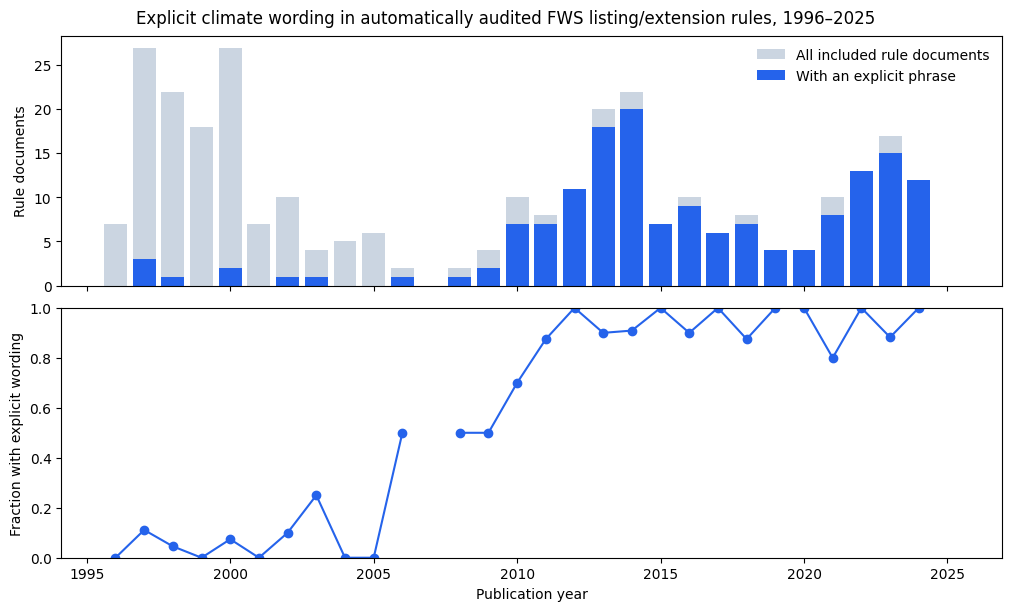

In [6]:
flags = passages.groupby('document_number')[['explicit_match', 'broader_match']].max()
baseline = corpus[['document_number', 'year', 'title', 'html_url']].merge(
    flags, left_on='document_number', right_index=True, validate='one_to_one')
annual = baseline.groupby('year').agg(rules=('document_number', 'size'),
    explicit_mentions=('explicit_match', 'sum'), broader_mentions=('broader_match', 'sum'))
annual = annual.reindex(range(1996, 2026), fill_value=0)
annual['explicit_mention_fraction'] = annual.explicit_mentions / annual.rules.replace(0, np.nan)
baseline.to_csv(ROOT / 'results/keyword_baseline.csv', index=False)
annual.to_csv(ROOT / 'results/annual_keyword_baseline.csv')
display(annual)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)
axes[0].bar(annual.index, annual.rules, color='#cbd5e1', label='All included rule documents')
axes[0].bar(annual.index, annual.explicit_mentions, color='#2563eb', label='With an explicit phrase')
axes[0].set_ylabel('Rule documents'); axes[0].legend(frameon=False)
axes[1].plot(annual.index, annual.explicit_mention_fraction, marker='o', color='#2563eb')
axes[1].set(ylabel='Fraction with explicit wording', xlabel='Publication year', ylim=(0, 1))
fig.suptitle('Explicit climate wording in automatically audited FWS listing/extension rules, 1996–2025')
fig.savefig(ROOT / 'results/keyword_baseline.png', dpi=160)
plt.show()

## Two recorded guided checks
`review/passage_labels.csv` records the butterfly passage judgment and the later puffleg response,
with reasons, source passage IDs, and review context. The puffleg response followed a worked
example. It supports a recorded document resolution, while the butterfly record remains a
passage judgment. These checks do not provide a representative or blinded accuracy estimate.


In [7]:
from hashlib import sha256
labels = pd.read_csv(ROOT / 'review/passage_labels.csv', keep_default_na=False)
lookup = passages.set_index('passage_id')
assert labels.passage_id.is_unique
for row in labels.itertuples():
    source = lookup.loc[row.passage_id]
    assert source.document_number == row.document_number
    assert sha256(source.text.encode()).hexdigest() == row.evidence_sha256
    assert row.human_label in ['agency_threat', 'mention_only', 'uncertain']
    assert row.reviewer and row.reason and row.review_context
    for context_id in filter(None, row.context_passage_ids.split(';')):
        assert lookup.loc[context_id, 'document_number'] == row.document_number
initial_labels = pd.read_csv(ROOT / 'review/document_classifications.csv')[['document_number','classification']]
checks = labels.merge(initial_labels.rename(columns={'classification':'initial_model_label'}),
                      on='document_number', validate='one_to_one')
display(checks[['document_number','initial_model_label','human_label','document_resolution',
                'reviewer','reason','review_context','source_url']])

,document_number,initial_model_label,human_label,document_resolution,reviewer,reason,review_context,source_url
0,2020-07856,agency_threat,agency_threat,,Yanghong Liu,The agency explicitly expects climate change t...,Guided excerpt judgment before preparation of ...,https://www.federalregister.gov/documents/2020...
1,2010-18018,uncertain,agency_threat,agency_threat,Yanghong Liu,I classify this as agency_threat because prote...,Endorsed after a source summary and a model-ge...,https://www.federalregister.gov/documents/2010...


## Retrieve words, then interpret agency reasoning
The original pattern misses variations such as **climate changes**. `climate_evidence.py` adds
plural, hyphenated, and other explicit aliases and retains the broader mechanism search.
The union retrieves 2,515 passages in 174 documents. A reading score prioritizes passages;
it is not a threat classifier. Difficult cases use additional passages and context.

The coding model prepared the initial document classifications and five Delach comparisons;
it also organized Yanghong's confirmed views into the English conclusion. Yanghong chose the
scope and provided two guided checks, with reasons translated into English. The puffleg response followed a source summary and worked example; it is not an
independent or blinded validation. Final results apply its recorded resolution while preserving
the original model predictions in `review/document_classifications.csv`.

The saved classification set assigns one document label with an exact evidence passage,
a reason, and any additional context IDs in `review/document_classifications.csv`.
The notebook validates and replays these annotations. It checks quotation text and hashes before
using a label; changed sources or retrieval candidates require renewed review.

`agency_threat` means at least one qualifying agency passage was found for a newly protected
target. It does not assign the label to every species in a multi-species rule.
`no_search_evidence` means no passage matched the recorded search union. It is not an agency
denial, and implicit climate mechanisms could be missed. The timing below covers retrieval and
replay, not semantic classification speed or accuracy.

In [8]:
from climate_evidence import retrieve_evidence, replay_judgments, independent_cases
started = perf_counter()
evidence = retrieve_evidence(passages)
evidence_seconds = perf_counter() - started
started = perf_counter()
agency_documents, agency_annual, agency_periods = replay_judgments(corpus, passages, evidence, ROOT)
replay_seconds = perf_counter() - started
print(f"Search union: {len(evidence):,} passages, {evidence.document_number.nunique()} documents.")
print(f"Retrieval: {evidence_seconds:.3f} s; validating/replaying saved labels: {replay_seconds:.3f} s.")
print("These timings cover retrieval and replay, not semantic classification speed or accuracy.")
display(agency_documents.classification.value_counts().rename_axis('source interpretation').to_frame('rules'))
display(agency_periods)
display(agency_documents[agency_documents.classification.eq('uncertain')][
    ['document_number','title','reason','evidence_passage_id','source_url']])

Search union: 2,515 passages, 174 documents.
Retrieval: 1.045 s; validating/replaying saved labels: 0.044 s.
These timings cover retrieval and replay, not semantic classification speed or accuracy.


,rules
source interpretation,
agency_threat,140
no_search_evidence,129
mention_only,21
uncertain,13


classification,agency_threat,mention_only,uncertain,no_search_evidence,rules,source_supported_fraction
period,,,,,,
1996–2005,2,9,6,116,133,0.015038
2006–2015,63,6,6,11,86,0.732558
2016–2025,75,6,1,2,84,0.892857


,document_number,title,reason,evidence_passage_id,source_url
36,98-6998,Endangered and Threatened Wildlife and Plants;...,Climatic changes may contribute to lamb mortal...,98-6998:p0100,https://www.federalregister.gov/documents/1998...
99,00-29423,Endangered and Threatened Species; Final Endan...,The response discusses temperature effects on ...,00-29423:p0170,https://www.federalregister.gov/documents/2000...
110,02-5274,Endangered and Threatened Wildlife and Plants;...,Past drought is discussed as a possible confou...,02-5274:p0091,https://www.federalregister.gov/documents/2002...
112,02-14730,Endangered and Threatened Wildlife and Plants;...,The agency says IF climate change contributes ...,02-14730:p0075,https://www.federalregister.gov/documents/2002...
119,03-6454,Endangered and Threatened Wildlife and Plants;...,A regional disease-climate hypothesis is extra...,03-6454:p0151,https://www.federalregister.gov/documents/2003...
129,05-15718,Endangered and Threatened Wildlife and Plants;...,Climate-related forage changes are one hypothe...,05-15718:p0200,https://www.federalregister.gov/documents/2005...
158,2011-25539,Endangered and Threatened Wildlife and Plants;...,The hits discuss dynamic critical habitat and ...,2011-25539:p0171,https://www.federalregister.gov/documents/2011...
174,2013-19386,Endangered and Threatened Wildlife and Plants;...,One section calls climate change a threat whil...,2013-19386:p0139,https://www.federalregister.gov/documents/2013...
191,2014-07414,Endangered and Threatened Wildlife and Plants;...,The response rejects climate change as a threa...,2014-07414:p0118,https://www.federalregister.gov/documents/2014...
194,2014-10049,Endangered and Threatened Wildlife and Plants;...,The agency says climate change could impact th...,2014-10049:p0025,https://www.federalregister.gov/documents/2014...


## Cases that changed how the output should be used
**Island marble butterfly.** The agency expects climate change to worsen storm-surge impacts,
even though it cannot establish a change in emergence timing. Uncertainty about one mechanism
does not cancel a separate recognized risk, so the passage supports `agency_threat`.

**Lynx and pygmy rabbit.** The 2000 lynx rule includes a public claim about global warming, but
the agency explicitly rejects evidence that it threatens the lynx. The pygmy-rabbit hit describes
historical biogeography. Both are real keyword hits, but using the positive keyword flag as a
threat label would be wrong.

**Virginia sneezeweed.** The agency directly calls **climate changes** a potential threat.
The original pattern misses this plural form; the alias search recovers it.

**Gierisch mallow.** This rule remains `uncertain`: one section calls climate change a threat,
while its climate summary says the evidence is too speculative to establish a future threat.
Both passages are retained. These cases illustrate interpretation and retrieval errors;
they do not provide a representative accuracy estimate.

**Black-breasted puffleg: resolving a model disagreement.** The original model label was
`uncertain`, emphasizing the rejection of climate change as a threat by itself and the buffering
effect of reserves. Yanghong endorsed `agency_threat` for the reason recorded above. The source
also expects CO2 emissions to spread invasive plants and damage habitat (`2010-18018:p0105`).
Factor E discusses potential climate-related changes in plant composition, while retaining the
role of reserves (`p0107`). Under our criterion, a potential adverse contribution can count even
when it is not the main listing driver or some effects are buffered. The recorded resolution
therefore changes this rule to `agency_threat`. It does not claim that climate change alone
caused the listing or that all CO2 mentions qualify. The lesson is to distinguish a limited
negation and mitigation from a complete rejection of every risk pathway.
[Official source](https://www.govinfo.gov/content/pkg/FR-2010-07-27/html/2010-18018.htm).


In [9]:
examples = ['2020-07856','00-7145','03-5076','98-29303','2013-19386','2010-18018']
display(agency_documents[agency_documents.document_number.isin(examples)][
    ['document_number','classification','evidence_passage_id','evidence_text','reason','source_url']])

,document_number,classification,evidence_passage_id,evidence_text,reason,source_url
52,98-29303,agency_threat,98-29303:p0048,"Invasion of an exotic species, purple loosestr...",The agency explicitly calls natural or human-c...,https://www.federalregister.gov/documents/1998...
89,00-7145,mention_only,00-7145:p0174,we do not agree that global warming or the exp...,The agency explicitly says there is no evidenc...,https://www.federalregister.gov/documents/2000...
118,03-5076,mention_only,03-5076:p0036,Gradual climate change affecting the distribut...,The climate reference explains late-Holocene r...,https://www.federalregister.gov/documents/2003...
144,2010-18018,agency_threat,2010-18018:p0105,"Emissions of CO2, considered to be the most si...",I classify this as agency_threat because prote...,https://www.federalregister.gov/documents/2010...
174,2013-19386,uncertain,2013-19386:p0139,"In summary, the future effects of global clima...",One section calls climate change a threat whil...,https://www.federalregister.gov/documents/2013...
247,2020-07856,agency_threat,2020-07856:p0199,Due to the small number of individuals remaini...,The agency assessment links climate-related ch...,https://www.federalregister.gov/documents/2020...


## Recognition is more common in later rules
The source review identifies an agency climate-risk contribution in **140 of 303 rules (46.2%)**.
Another **13** have unresolved interpretations, **21** have retrieved wording without a qualifying
finding, and **129** have no search-union evidence. The last group is not a set of verified negative
species. The original explicit-wording baseline is **160 of 303 (52.8%)** after the turtle correction.

The source-supported share is 2/133 in 1996–2005, 63/86 in 2006–2015, and 75/84 in 2016–2025.
This describes the records we retrieved and interpreted. It does not establish why recognition
changed. Species and rule composition, multi-species documents, changing vocabulary, and retrieval
limitations can affect the pattern. A year with no eligible documents has no estimated proportion.
The shaded band adds unresolved source interpretations; it is **not a confidence interval** and
does not account for all interpretation errors or missed implicit evidence.

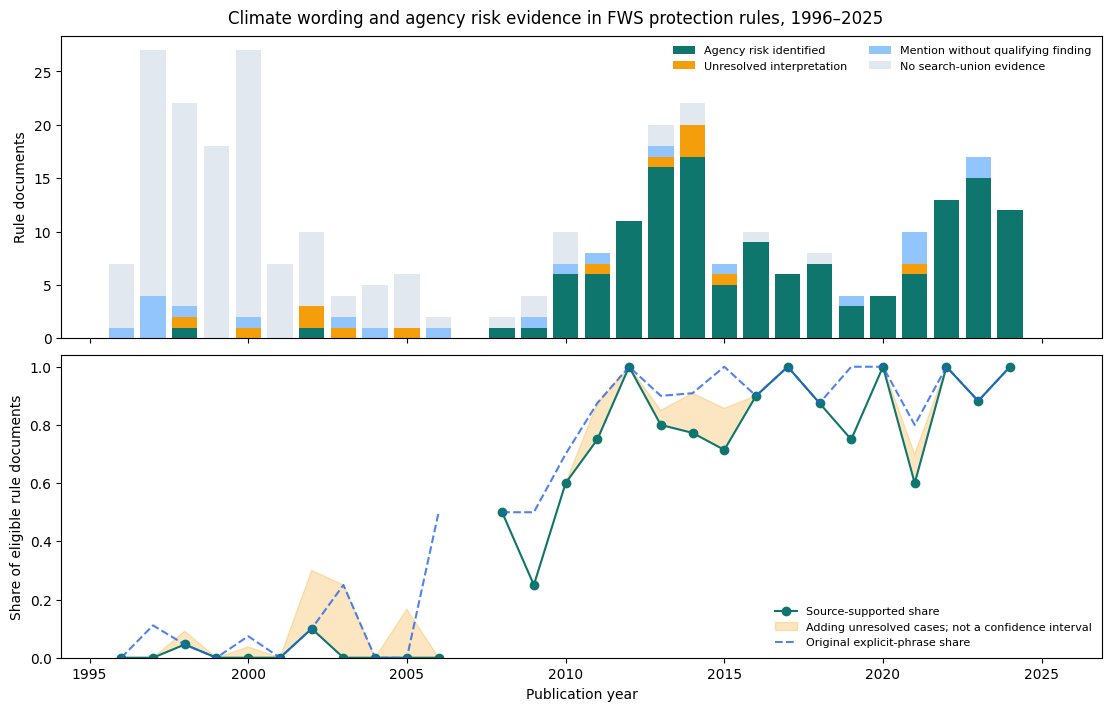

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, constrained_layout=True)
bottom = np.zeros(len(agency_annual))
styles = [('agency_threat', '#0f766e', 'Agency risk identified'),
          ('uncertain', '#f59e0b', 'Unresolved interpretation'),
          ('mention_only', '#93c5fd', 'Mention without qualifying finding'),
          ('no_search_evidence', '#e2e8f0', 'No search-union evidence')]
for key, color, label in styles:
    axes[0].bar(agency_annual.index, agency_annual[key], bottom=bottom, color=color, label=label)
    bottom += agency_annual[key].to_numpy()
axes[0].set_ylabel('Rule documents')
axes[0].legend(frameon=False, fontsize=8, ncol=2, loc='upper right')
x = agency_annual.index.to_numpy()
lower = agency_annual.source_supported_fraction.to_numpy()
upper = agency_annual.supported_plus_uncertain_fraction.to_numpy()
axes[1].plot(x, lower, marker='o', color='#0f766e', label='Source-supported share')
axes[1].fill_between(x, lower, upper, color='#f59e0b', alpha=.25,
                     label='Adding unresolved cases; not a confidence interval')
axes[1].plot(annual.index, annual.explicit_mention_fraction, color='#2563eb', linestyle='--',
             alpha=.8, label='Original explicit-phrase share')
axes[1].set(xlabel='Publication year', ylabel='Share of eligible rule documents', ylim=(0, 1.04))
axes[1].legend(frameon=False, fontsize=8, loc='lower right')
fig.suptitle('Climate wording and agency risk evidence in FWS protection rules, 1996–2025')
fig.savefig(ROOT/'results/agency_climate_evidence.png', dpi=160)
plt.show()

## Compare like with like in the independent dataset
Read `sources/delach_metadata.csv` before interpreting the columns. The dataset has one row per
endangered animal species, including both FWS and NMFS jurisdictions. `Date` is the year of its
most recent official ESA document, and `CC_Discuss` concerns discussion of a potential climate threat.
`Discuss_Level` concerns management-action discussion; it is a different outcome.

Our full corpus includes plants and threatened listings, uses initial rules, and counts documents.
Its raw percentage is therefore not directly comparable with Delach's per-species percentage.
The table below records this difference rather than explaining away a numerical discrepancy.

A species name in a rule is not enough to establish a listing target. A valid comparison needs
the target, document, and outcome to be checked.

The additional case table checks the actual listing target in the official SUMMARY for five
purposively selected animals. Four are single-species rules. The pygmy-rabbit rule concerns a DPS,
whose exact correspondence with the independent species row remains a limitation. Differences in year, document, geographic extent, and outcome prevent treating this small
table as an accuracy test. Equal years alone do
not prove that both studies read the same document.

In [11]:
delach = delach_data(ROOT)
print(f'Independent dataset: {len(delach)} species.')
display(delach.CC_Discuss.value_counts(dropna=False).to_frame('species'))
display(pd.DataFrame([
    {'source': 'Our corpus', 'unit': 'listing/new-range rule', 'taxa': 'animals and plants',
     'agency': 'FWS', 'time': 'publication date, 1996–2025', 'outcome': 'source-based agency risk classification'},
    {'source': 'Delach discussion dataset', 'unit': 'endangered animal species', 'taxa': 'animals',
     'agency': 'FWS and NMFS', 'time': 'most recent official ESA document', 'outcome': 'potential threat discussed'}]))
case_comparison = independent_cases(agency_documents, delach, ROOT)
display(case_comparison[['Scientific_Name','document_number','listing_rule_year',
    'Delach_most_recent_document_year','Delach_CC_Discuss','rule_label']]
    .rename(columns={'rule_label': 'rule_classification'}))
print('Purposive comparisons with different documents/outcomes; no agreement rate or accuracy is estimated.')


Independent dataset: 459 species.


,species
CC_Discuss,
Yes,294
No,165


,source,unit,taxa,agency,time,outcome
0,Our corpus,listing/new-range rule,animals and plants,FWS,"publication date, 1996–2025",source-based agency risk classification
1,Delach discussion dataset,endangered animal species,animals,FWS and NMFS,most recent official ESA document,potential threat discussed


,Scientific_Name,document_number,listing_rule_year,Delach_most_recent_document_year,Delach_CC_Discuss,rule_classification
0,Antrobia culveri,02-20339,2002,2011,Yes,agency_threat
1,Brachylagus idahoensis,03-5076,2003,2013,No,mention_only
2,Cicindelidia floridana,2016-23945,2016,2016,Yes,agency_threat
3,Bombus affinis,2017-00195,2017,2018,Yes,agency_threat
4,Eumops floridanus,2013-23401,2013,2013,Yes,agency_threat


Purposive comparisons with different documents/outcomes; no agreement rate or accuracy is estimated.


## Check how reasonable choices change the answer
The recorded scope includes genuinely new geographic or population protection. Excluding those
six rules changes the result from 140/303 (46.2%) to 139/297 (46.8%). Excluding the five first
permanent rules following temporary emergency protection gives 139/298 (46.6%). These choices
affect the denominator without changing the broad pattern.

Counting all 13 unresolved interpretations as risk findings gives 153/303 (50.5%). This tests a
labeling choice; it is not a confidence interval or an upper bound on true recognition. It does
not account for interpretation errors or climate reasoning missed by the retrieval process.

In [12]:
from climate_evidence import scope_sensitivity
sensitivity = scope_sensitivity(agency_documents, ROOT)
display(sensitivity.style.format({'fraction':'{:.1%}'}))

,scenario,counted_risk_rules,rules,fraction,choice_type
0,Recorded scope,140,303,46.2%,Baseline
1,Exclude new geographic/population protection,139,297,46.8%,Corpus choice
2,Exclude first permanent rules after temporary emergencies,139,298,46.6%,Corpus choice
3,Count unresolved interpretations as risk findings,153,303,50.5%,Label choice; not an error bound


## What the evidence supports
In this dataset, later FWS rules more often identify climate-related risks. The puffleg check
showed me why context matters: protected areas can reduce risk without eliminating it, so one
negative sentence is not enough to classify the whole rule.

I remain cautious about the figure of 140 out of 303 rules (46.2%). Some of the 129 rules with
no retrieved evidence may discuss risks in other words, and two guided checks do not establish
overall classification accuracy.

My next step would be to sample the rules with no retrieved evidence and read them for missed
climate mechanisms. I would then revisit the 13 uncertain cases and check whether any corrections
change the overall conclusion.
